=== 数据预览 ===
   Year  Crude Birth Rate (No. of known live births per 1,000 populatioin)  \
0  1981                                               16.8                   
1  1982                                               16.4                   
2  1983                                               15.6                   
3  1984                                               14.4                   
4  1985                                               14.0                   

   Male Known Births  Female Known Births  
0              44610                42141  
1              44351                41769  
2              42836                40457  
3              39943                37354  
4              39296                36830  

=== 1. 描述性统计量 ===
count    44.000000
mean     10.025000
std       3.252414
min       4.400000
25%       7.525000
50%       9.750000
75%      12.375000
max      16.800000
Name: Crude Birth Rate (No. of known live births per 1,000 populatioin), dtype: flo

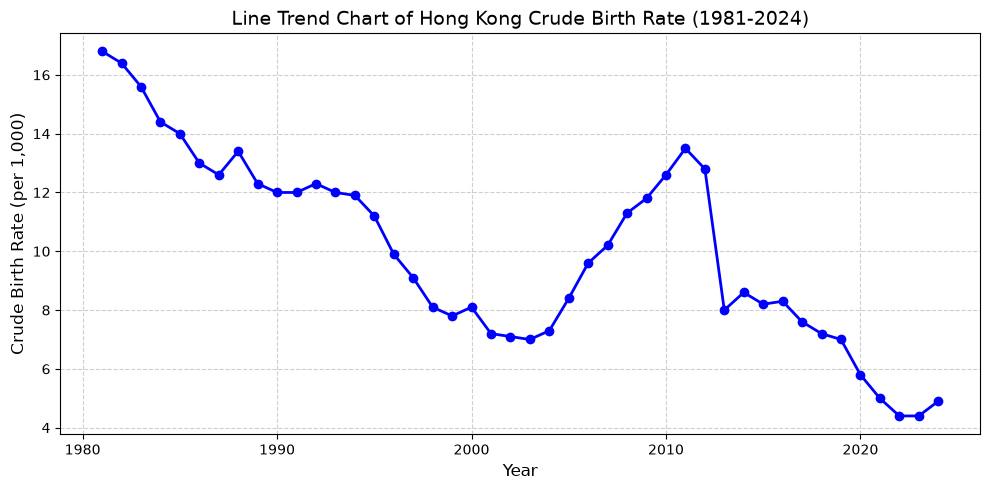


=== 2. 平稳性检验 (ADF Test) ===
--- Original CBR ADF 检验结果 ---
ADF Statistic: -1.7077
p-value: 0.4272
   Critical Value (1%): -3.5966
   Critical Value (5%): -2.9333
   Critical Value (10%): -2.6050
结论: 无法拒绝原假设，序列是非平稳的。

--- 1st Difference of CBR ADF 检验结果 ---
ADF Statistic: -5.2190
p-value: 0.0000
   Critical Value (1%): -3.5966
   Critical Value (5%): -2.9333
   Critical Value (10%): -2.6050
结论: 拒绝原假设，序列是平稳的。



/tmp/ipykernel_2964/1287604406.py:53: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
/tmp/ipykernel_2964/1287604406.py:53: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


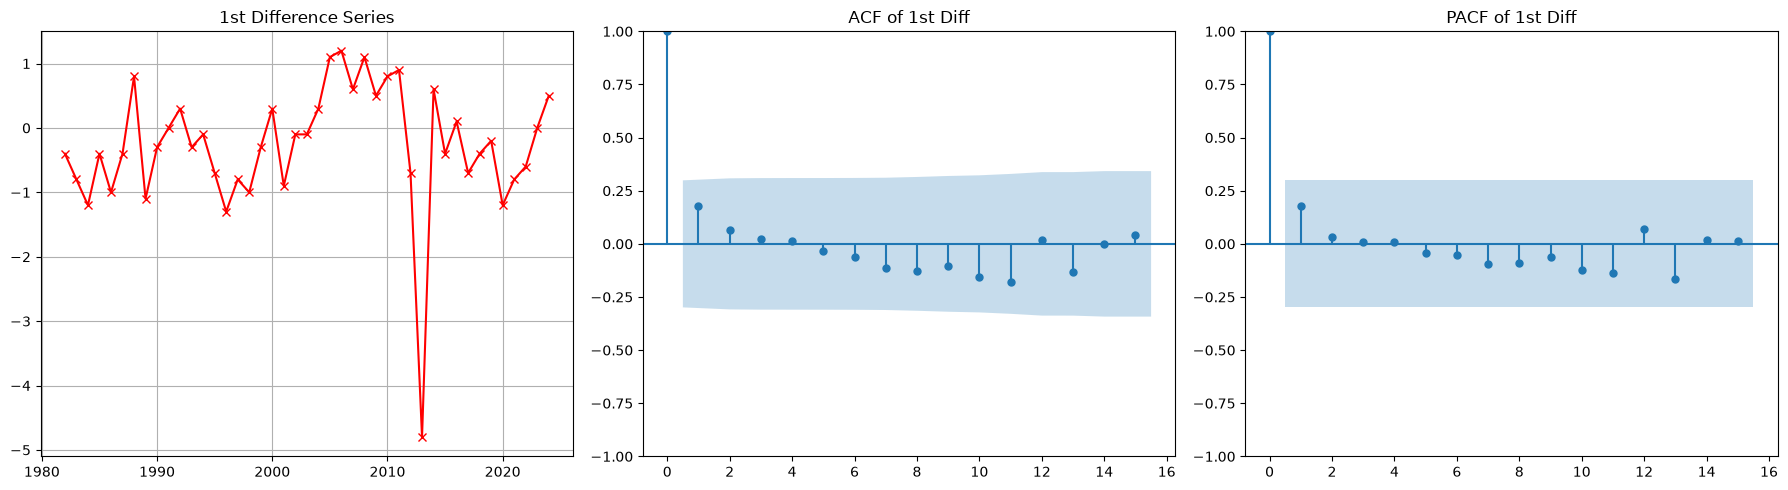


=== 3. ARIMA 模型拟合与定阶 ===
ARIMA(0,1,0) -> AIC: 124.99
ARIMA(0,1,1) -> AIC: 124.82
ARIMA(0,1,2) -> AIC: 126.34
ARIMA(1,1,0) -> AIC: 124.40
ARIMA(1,1,1) -> AIC: 126.04
ARIMA(1,1,2) -> AIC: 128.04
ARIMA(2,1,0) -> AIC: 126.13
ARIMA(2,1,1) -> AIC: 128.04
ARIMA(2,1,2) -> AIC: 130.04

最优选择: ARIMA(1, 1, 0)，其 AIC 值为最小: 124.40
                                                       SARIMAX Results                                                       
Dep. Variable:     Crude Birth Rate (No. of known live births per 1,000 populatioin)   No. Observations:                   44
Model:                                                                ARIMA(1, 1, 0)   Log Likelihood                 -60.199
Date:                                                               Thu, 12 Nov 2026   AIC                            124.398
Time:                                                                       11:31:45   BIC                            127.921
Sample:                                            

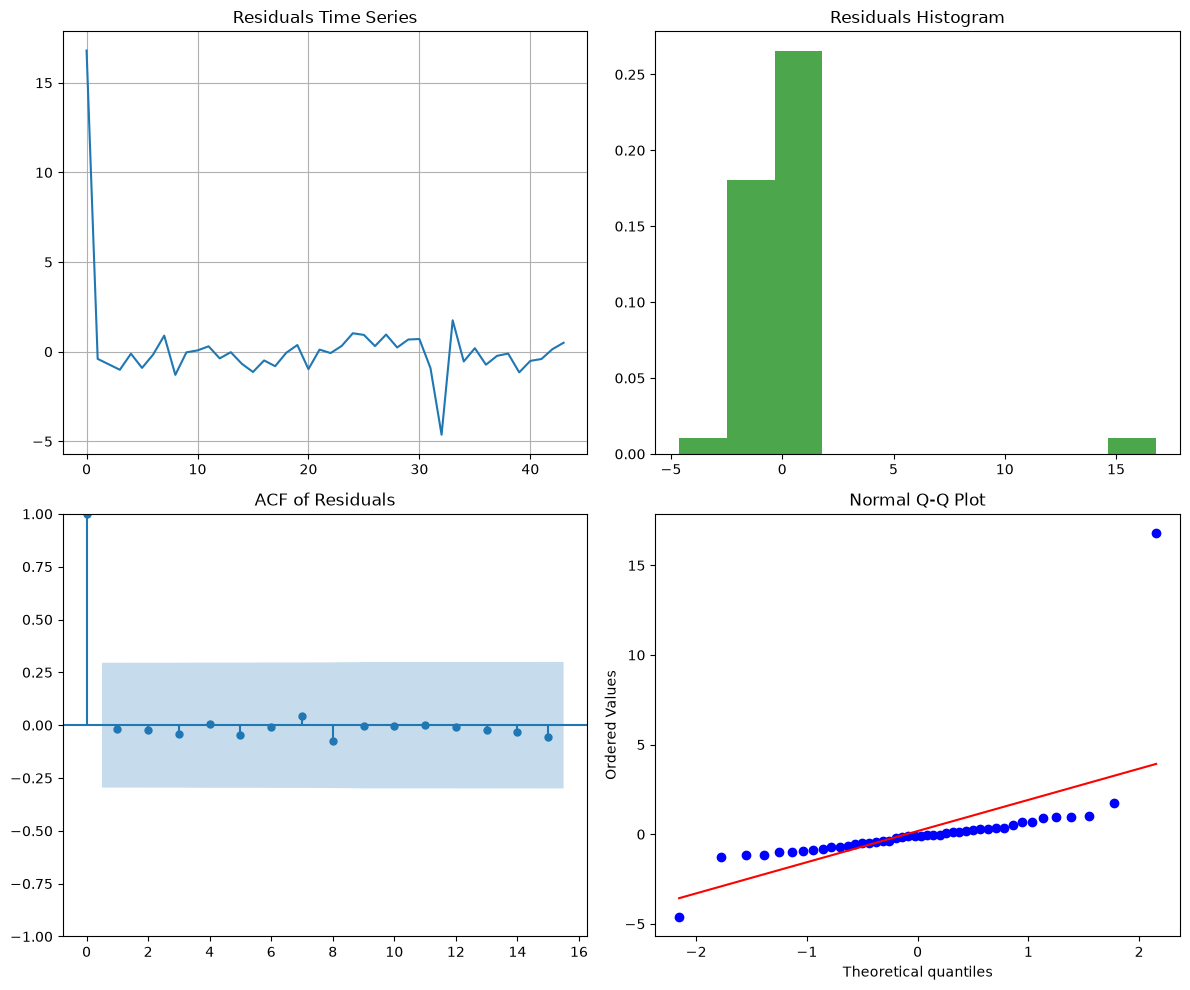


=== 5. 未来 5 年超前预测 (2025 - 2029) ===
   Year  Predicted_CBR  Lower_CI   Upper_CI
0  2025       5.020010  3.098185   6.941836
1  2026       5.048815  1.987346   8.110284
2  2027       5.055729  1.107093   9.004365
3  2028       5.057388  0.372935   9.741842
4  2029       5.057787 -0.264683  10.380256


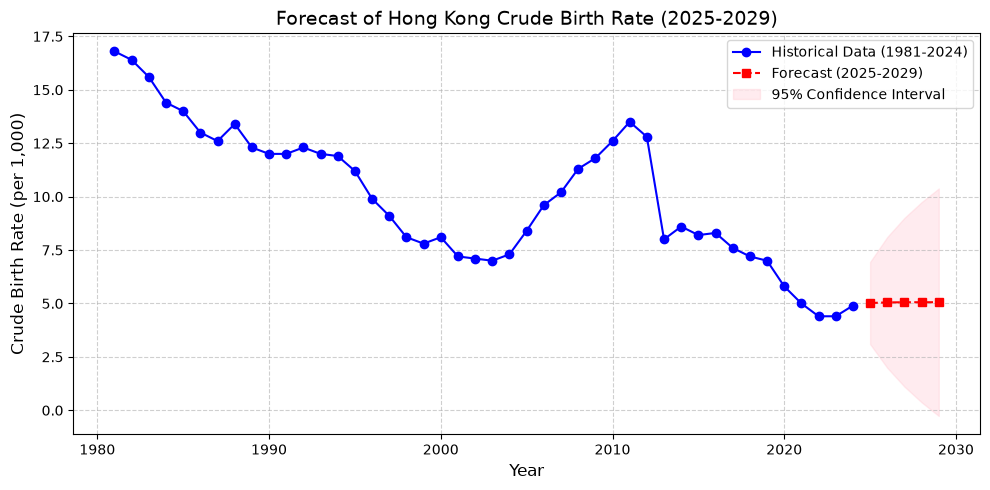

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# 1. 读取数据与预处理
file_path = "出生率数据.csv"
df = pd.read_csv(file_path)

# 查看数据基本信息
print("=== 数据预览 ===")
print(df.head())

# 提取年份和粗出生率 (Crude Birth Rate)
years = df["Year"]
cbr = df[
    "Crude Birth Rate (No. of known live births per 1,000 populatioin)"
]  # 注意保持原表格列名

# =====================================================================
# 第一部分：描述性统计与时序可视化
# =====================================================================
print("\n=== 1. 描述性统计量 ===")
stats = cbr.describe()
print(stats)
print(f"标准差 (Std): {cbr.std():.4f}")
print(
    f"最小值: {cbr.min()} (年份: {years[cbr.idxmin()]}年), 最大值: {cbr.max()} (年份: {years[cbr.idxmax()]}年)"
)

# 绘制原始序列时序图
plt.figure(figsize=(10, 5))
plt.plot(years, cbr, marker="o", linestyle="-", color="b", linewidth=2)
plt.title(
    "Line Trend Chart of Hong Kong Crude Birth Rate (1981-2024)", fontsize=14
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Crude Birth Rate (per 1,000)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("cbr_trend.png", dpi=300)
plt.show()

# =====================================================================
# 第二部分：平稳性检验与一阶差分处理 (ADF Test)
# =====================================================================
print("\n=== 2. 平稳性检验 (ADF Test) ===")


def check_stationarity(series, name="Series"):
  result = adfuller(series.dropna())
  print(f"--- {name} ADF 检验结果 ---")
  print(f"ADF Statistic: {result[0]:.4f}")
  print(f"p-value: {result[1]:.4f}")
  for key, value in result[4].items():
    print(f"   Critical Value ({key}): {value:.4f}")
  if result[1] < 0.05:
    print(f"结论: 拒绝原假设，序列是平稳的。\n")
  else:
    print(f"结论: 无法拒绝原假设，序列是非平稳的。\n")


check_stationarity(cbr, "Original CBR")

# 进行一阶差分
cbr_diff1 = cbr.diff().dropna()
check_stationarity(cbr_diff1, "1st Difference of CBR")

# 绘制一阶差分后的时序图、ACF 与 PACF
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(
    years[1:], cbr_diff1, color="r", marker="x"
)  # 注意差分后少了一个观测值
axes[0].set_title("1st Difference Series")
axes[0].grid(True)

plot_acf(cbr_diff1, ax=axes[1], lags=15)
axes[1].set_title("ACF of 1st Diff")

plot_pacf(cbr_diff1, ax=axes[2], lags=15, method="ywm")
axes[2].set_title("PACF of 1st Diff")

plt.tight_layout()
plt.savefig("cbr_diff_acf_pacf.png", dpi=300)
plt.show()

# =====================================================================
# 第三部分：ARIMA 模型自动/手动定阶与拟合
# =====================================================================
print("\n=== 3. ARIMA 模型拟合与定阶 ===")

# 遍历寻找 AIC 最小的 ARIMA 模型
best_aic = float("inf")
best_order = None
best_model = None

for p in range(0, 3):
  for d in range(1, 2):  # 根据 ADF 检验，d=1
    for q in range(0, 3):
      try:
        model = ARIMA(cbr, order=(p, d, q))
        results = model.fit()
        print(f"ARIMA({p},{d},{q}) -> AIC: {results.aic:.2f}")
        if results.aic < best_aic:
          best_aic = results.aic
          best_order = (p, d, q)
          best_model = results
      except:
        continue

print(
    f"\n最优选择: ARIMA{best_order}，其 AIC 值为最小: {best_aic:.2f}"
)
print(best_model.summary())

# =====================================================================
# 第四部分：模型残差诊断
# =====================================================================
print("\n=== 4. 残差诊断检验 ===")
residuals = best_model.resid

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
# 残差时序图
axes[0, 0].plot(residuals)
axes[0, 0].set_title("Residuals Time Series")
axes[0, 0].grid(True)
# 残差直方图
axes[0, 1].hist(residuals, bins=10, density=True, alpha=0.7, color="g")
axes[0, 1].set_title("Residuals Histogram")
# 残差 ACF
plot_acf(residuals, ax=axes[1, 0], lags=15)
axes[1, 0].set_title("ACF of Residuals")
# Q-Q 图
import scipy.stats as stats

stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.savefig("residuals_diagnostics.png", dpi=300)
plt.show()

# =====================================================================
# 第五部分：未来超前预测 (Forecasting)
# =====================================================================
print("\n=== 5. 未来 5 年超前预测 (2025 - 2029) ===")

forecast_steps = 5
forecast_obj = best_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast_obj.predicted_mean
forecast_ci = forecast_obj.conf_int(alpha=0.05)  # 95% 置信区间

# 构造预测年份标签
future_years = range(years.iloc[-1] + 1, years.iloc[-1] + 1 + forecast_steps)

forecast_df = pd.DataFrame(
    {
        "Year": future_years,
        "Predicted_CBR": forecast_mean.values,
        "Lower_CI": forecast_ci.iloc[:, 0].values,
        "Upper_CI": forecast_ci.iloc[:, 1].values,
    }
)
print(forecast_df)

# 绘制预测结果图
plt.figure(figsize=(10, 5))
plt.plot(years, cbr, label="Historical Data (1981-2024)", color="b", marker="o")
plt.plot(
    future_years,
    forecast_mean,
    label="Forecast (2025-2029)",
    color="r",
    marker="s",
    linestyle="--",
)
plt.fill_between(
    future_years,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="pink",
    alpha=0.3,
    label="95% Confidence Interval",
)
plt.title(
    "Forecast of Hong Kong Crude Birth Rate (2025-2029)", fontsize=14
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Crude Birth Rate (per 1,000)", fontsize=12)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("cbr_forecast.png", dpi=300)
plt.show()